In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Dataset, random_split
import torch.optim as optim

import pandas as pd
import math
import os
from PIL import Image
import matplotlib.pyplot as plt

# Verificar si CUDA está disponible y definir el dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


# Creación de dataloaders

# Patch embedding and Positional Embedding implementation

In [ ]:
def get_positional_encoding(d_model, max_sequence_length):
    """
    Generate sinusoidal positional encodings.

    Parameters
    ----------
    d_model : int
        The dimensionality of the embedding space.

    max_sequence_length : int
        The maximum length of the sequence for which to generate positional encodings.

    Returns
    -------
    torch.Tensor
        A tensor containing positional encodings of shape (max_sequence_length, d_model).
    """
    # Ensure d_model is an even number
    if d_model % 2 != 0:
        raise ValueError("d_model should be an even number")

    # Create indices for even dimensions
    even_i = torch.arange(0, d_model, 2).float().to(device)

    # Calculate the denominator for sinusoidal functions
    denominator = torch.pow(10000, even_i / d_model)

    # Create positions from 0 to max_sequence_length-1
    position = torch.arange(max_sequence_length).reshape(max_sequence_length, 1).to(device)

    # Calculate the sinusoidal positional encodings
    even_PE = torch.sin(position / denominator)
    odd_PE = torch.cos(position / denominator)

    # Stack even and odd positional encodings together
    stacked = torch.stack([even_PE, odd_PE], dim=2)

    # Flatten the stacked tensor to shape (max_sequence_length, d_model)
    PE = torch.flatten(stacked, start_dim=1, end_dim=2)

    return PE



In [ ]:
class PatchEmbed(nn.Module):
    """Split image into patches and then embed them.

    Parameters
    ----------
    img_size : int
        Size of the image (it is a square).

    patch_size : int
        Size of the patch (it is a square).

    in_chans : int
        Number of input channels.

    embed_dim : int
        The embedding dimension.

    Attributes
    ----------
    n_patches : int
        Number of patches inside of our image.

    proj : nn.Conv2d
        Convolutional layer that does both the splitting into patches
        and their embedding.

    pos_embedding : torch.Tensor
        Positional encoding for each patch.
    """
    def __init__(self, img_size, patch_size, in_chans=3, embed_dim=768):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.n_patches = (img_size // patch_size) ** 2
        self.embed_dim = embed_dim

        # Initialize the convolutional layer to create patch embeddings
        self.proj = nn.Conv2d(
            in_chans,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
        ).to(device)

        # Generate the positional encoding for the patches
        self.positional_encoding = get_positional_encoding(embed_dim, self.n_patches).to(device)

    def forward(self, x):
        """Run forward pass.

        Parameters
        ----------
        x : torch.Tensor
            Shape `(n_samples, in_chans, img_size, img_size)`.

        Returns
        -------
        torch.Tensor
            Shape `(n_samples, n_patches, embed_dim)`.
        """
        x = x.to(device)  # Asegúrate de que el tensor de entrada esté en el dispositivo correcto
        x = self.proj(x)  # (n_samples, embed_dim, n_patches ** 0.5, n_patches ** 0.5)
        x = x.flatten(2)  # (n_samples, embed_dim, n_patches)
        x = x.transpose(1, 2)  # (n_samples, n_patches, embed_dim)

        # Add positional encoding
        # Repeat the positional encoding for each batch
        pos_enc = self.positional_encoding.unsqueeze(0).repeat(x.size(0), 1, 1)
        x = x + pos_enc

        return x


# Attention module

In [ ]:
class Attention(nn.Module):
    """Attention mechanism.

    Parameters
    ----------
    dim : int
        The input and out dimension of per token features.

    n_heads : int
        Number of attention heads.

    qkv_bias : bool
        If True then we include bias to the query, key and value projections.

    attn_p : float
        Dropout probability applied to the query, key and value tensors.

    proj_p : float
        Dropout probability applied to the output tensor.


    Attributes
    ----------
    scale : float
        Normalizing consant for the dot product.

    qkv : nn.Linear
        Linear projection for the query, key and value.

    proj : nn.Linear
        Linear mapping that takes in the concatenated output of all attention
        heads and maps it into a new space.

    attn_drop, proj_drop : nn.Dropout
        Dropout layers.
    """
    def __init__(self, dim, n_heads=12, qkv_bias=True, attn_p=0., proj_p=0.):
        super().__init__()
        self.n_heads = n_heads
        self.dim = dim
        self.head_dim = dim // n_heads
        self.scale = self.head_dim ** -0.5

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias).to(device)
        self.attn_drop = nn.Dropout(attn_p).to(device)
        self.proj = nn.Linear(dim, dim).to(device)
        self.proj_drop = nn.Dropout(proj_p).to(device)

    def forward(self, x):
        """Run forward pass.

        Parameters
        ----------
        x : torch.Tensor
            Shape `(n_samples, n_patches + 1, dim)`.

        Returns
        -------
        torch.Tensor
            Shape `(n_samples, n_patches + 1, dim)`.
        """
        x = x.to(device)
        n_samples, n_tokens, dim = x.shape

        if dim != self.dim:
            raise ValueError

        qkv = self.qkv(x)  # (n_samples, n_patches + 1, 3 * dim)
        qkv = qkv.reshape(n_samples, n_tokens, 3, self.n_heads, self.head_dim)  # (n_samples, n_patches + 1, 3, n_heads, head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, n_samples, n_heads, n_patches + 1, head_dim)

        q, k, v = qkv[0], qkv[1], qkv[2]

        k_t = k.transpose(-2, -1)  # (n_samples, n_heads, head_dim, n_patches + 1)
        dp = (q @ k_t) * self.scale  # (n_samples, n_heads, n_patches + 1, n_patches + 1)
        attn = dp.softmax(dim=-1)  # (n_samples, n_heads, n_patches + 1, n_patches + 1)
        attn = self.attn_drop(attn)

        weighted_avg = attn @ v  # (n_samples, n_heads, n_patches + 1, head_dim)
        weighted_avg = weighted_avg.transpose(1, 2)  # (n_samples, n_patches + 1, n_heads, head_dim)
        weighted_avg = weighted_avg.flatten(2)  # (n_samples, n_patches + 1, dim)

        x = self.proj(weighted_avg)  # (n_samples, n_patches + 1, dim)
        x = self.proj_drop(x)  # (n_samples, n_patches + 1, dim)

        return x


# MultiLayer Perceptron Module

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_features, hidden_features, out_features, p=0.):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden_features).to(device)
        self.act = nn.GELU().to(device)
        self.fc2 = nn.Linear(hidden_features, out_features).to(device)
        self.drop = nn.Dropout(p).to(device)

    def forward(self, x):
        x = x.to(device)  # Asegúrate de que el tensor de entrada esté en el dispositivo correcto

        x = self.fc1(x)  # (n_samples, n_patches + 1, hidden_features)
        x = self.act(x)  # (n_samples, n_patches + 1, hidden_features)
        x = self.drop(x)  # (n_samples, n_patches + 1, hidden_features)
        x = self.fc2(x)  # (n_samples, n_patches + 1, out_features)
        x = self.drop(x)  # (n_samples, n_patches + 1, out_features)

        return x


# Transformer block

In [ ]:
class Block(nn.Module):
    """Transformer block.

    Parameters
    ----------
    dim : int
        Embeddinig dimension.

    n_heads : int
        Number of attention heads.

    mlp_ratio : float
        Determines the hidden dimension size of the `MLP` module with respect
        to `dim`.

    qkv_bias : bool
        If True then we include bias to the query, key and value projections.

    p, attn_p : float
        Dropout probability.

    Attributes
    ----------
    norm1, norm2 : LayerNorm
        Layer normalization.

    attn : Attention
        Attention module.

    mlp : MLP
        MLP module.
    """
    def __init__(self, dim, n_heads, mlp_ratio=4.0, qkv_bias=True, p=0., attn_p=0.):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6).to(device)
        self.attn = Attention(
            dim,
            n_heads=n_heads,
            qkv_bias=qkv_bias,
            attn_p=attn_p,
            proj_p=p
        ).to(device)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6).to(device)
        hidden_features = int(dim * mlp_ratio)
        self.mlp = MLP(
            in_features=dim,
            hidden_features=hidden_features,
            out_features=dim,
        ).to(device)

    def forward(self, x):
        """Run forward pass.

        Parameters
        ----------
        x : torch.Tensor
            Shape `(n_samples, n_patches + 1, dim)`.

        Returns
        -------
        torch.Tensor
            Shape `(n_samples, n_patches + 1, dim)`.
        """
        x = x.to(device)
        x = x + self.attn(self.norm1(x).to(device))
        x = x + self.mlp(self.norm2(x).to(device))

        return x


# Complete visual transformer


In [ ]:
class VisionTransformer(nn.Module):

    def __init__(
        self,
        # patch size parameters
        img_size=96,
        patch_size=16,
        in_chans=3,
        embed_dim=768,

        n_classes=2,
        depth=12,
        n_heads=12,
        mlp_ratio=4.,
        qkv_bias=True,
        p=0.,
        attn_p=0.
    ):
        super().__init__()
        # Seteamos el patch embedding
        self.patch_embed = PatchEmbed(
            img_size=img_size,
            patch_size=patch_size,
            in_chans=in_chans,
            embed_dim=embed_dim,
        ).to(device)

        # Seteamos classify token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim)).to(device)
        self.pos_embed = nn.Parameter(
            torch.zeros(1, 1 + self.patch_embed.n_patches, embed_dim)
        ).to(device)
        self.pos_drop = nn.Dropout(p=p).to(device)

        self.blocks = nn.ModuleList(
            [
                Block(
                    dim=embed_dim,
                    n_heads=n_heads,
                    mlp_ratio=mlp_ratio,
                    qkv_bias=qkv_bias,
                    p=p,
                    attn_p=attn_p,
                ).to(device)
                for _ in range(depth)
            ]
        )
        self.norm = nn.LayerNorm(embed_dim, eps=1e-6).to(device)
        self.head = nn.Linear(embed_dim, n_classes).to(device)

    def forward(self, x):
        x = x.to(device)  # Asegúrate de que el tensor de entrada esté en el dispositivo correcto

        # Cantidad de muestras del batch
        n_samples = x.shape[0]

        # Aplicamos patch embed
        x = self.patch_embed(x)

        # Agregamos token cls, que almacena info contextual de toda la imagen tras pasar por el bloque de atención.
        cls_token = self.cls_token.expand(n_samples, -1, -1)  # (n_samples, 1, embed_dim)
        x = torch.cat((cls_token, x), dim=1)  # (n_samples, 1 + n_patches, embed_dim)
        x = x + self.pos_embed  # (n_samples, 1 + n_patches, embed_dim)
        x = self.pos_drop(x)

        for block in self.blocks:
            x = block(x)

        x = self.norm(x)

        cls_token_final = x[:, 0]  # just the CLS token
        x = self.head(cls_token_final)

        return x


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
import matplotlib.pyplot as plt

def train_and_plot(model, train_loader, val_loader, num_epochs, criterion, optimizer, scheduler, device):
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Training"):
            images, labels = images.to(device), labels.to(device)  # Mover imágenes y etiquetas al dispositivo
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accuracies.append(train_acc)

        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Validation"):
                images, labels = images.to(device), labels.to(device)  # Mover imágenes y etiquetas al dispositivo
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = correct / total
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        # Actualizar el scheduler con la métrica de validación
        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch+1}/{num_epochs}, Training Loss: {train_loss:.4f}, Training Accuracy: {train_acc:.4f}, Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}, Learning Rate: {current_lr:.6f}")

    # Plotting
    epochs = range(1, num_epochs + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss vs Epochs')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy vs Epochs')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Training with data augmentation

In [ ]:
#%% Definir transformaciones para las imágenes
transform = transforms.Compose([
    transforms.ToTensor(),
])


class CustomDataset(Dataset):
    def __init__(self, csv_file, root_dir, transform=None):
        self.labels_df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.rotations = [0, 90, 180, 270]

    def __len__(self):
        return len(self.labels_df) * len(self.rotations)

    def __getitem__(self, idx):
        img_idx = idx // len(self.rotations)
        rot_idx = idx % len(self.rotations)
        rotation = self.rotations[rot_idx]

        img_name = os.path.join(self.root_dir, self.labels_df.iloc[img_idx, 0] + '.tif')
        image = Image.open(img_name).convert('RGB')
        label = self.labels_df.iloc[img_idx, 1]

        if self.transform:
            image = self.transform(image)

        # Rotar la imagen
        if rotation != 0:
            image = transforms.functional.rotate(image, rotation)

        return image, label


In [ ]:
#  Paths
train_csv = 'train_labels.csv'  # Asegúrate de que el archivo CSV tenga columnas 'id' y 'label'
train_dir = 'train'
test_dir = 'test'

# Crear dataset completo
full_dataset = CustomDataset(csv_file=train_csv, root_dir=train_dir, transform=transform)

# Dividir el dataset en entrenamiento y validación (80% - 20%)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

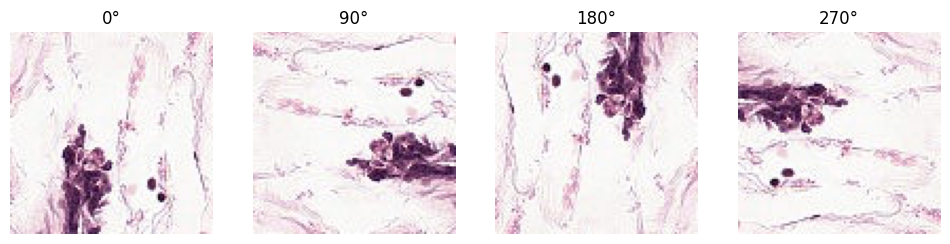

In [ ]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as F

# Obtener el primer elemento del dataset original y sus rotaciones
first_image, label = full_dataset[4]  # 0° rotación
first_image_90, _ = full_dataset[5]  # 90° rotación
first_image_180, _ = full_dataset[6]  # 180° rotación
first_image_270, _ = full_dataset[7]  # 270° rotación

# Convertir las imágenes de tensor a PIL para plotear
first_image_pil = F.to_pil_image(first_image)
first_image_90_pil = F.to_pil_image(first_image_90)
first_image_180_pil = F.to_pil_image(first_image_180)
first_image_270_pil = F.to_pil_image(first_image_270)

# Crear un plot con las 4 rotaciones
fig, axs = plt.subplots(1, 4, figsize=(12, 3))

axs[0].imshow(first_image_pil)
axs[0].set_title('0°')
axs[0].axis('off')

axs[1].imshow(first_image_90_pil)
axs[1].set_title('90°')
axs[1].axis('off')

axs[2].imshow(first_image_180_pil)
axs[2].set_title('180°')
axs[2].axis('off')

axs[3].imshow(first_image_270_pil)
axs[3].set_title('270°')
axs[3].axis('off')

plt.show()

In [ ]:
# Crear dataloaders para entrenamiento y validación
train_loader = DataLoader(train_dataset, batch_size=40, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=40, shuffle=True)

# Calcular la cantidad de datos
train_data_count = len(train_loader.dataset)
val_data_count = len(val_loader.dataset)

# Imprimir el tamaño de los dataloaders y la cantidad de datos
print(f'Tamaño del DataLoader de entrenamiento: {len(train_loader)} batches')
print(f'Cantidad de datos en el DataLoader de entrenamiento: {train_data_count} datos')
print(f'Tamaño del DataLoader de validación: {len(val_loader)} batches')
print(f'Cantidad de datos en el DataLoader de validación: {val_data_count} datos')

Tamaño del DataLoader de entrenamiento: 17602 batches
Cantidad de datos en el DataLoader de entrenamiento: 704080 datos
Tamaño del DataLoader de validación: 4401 batches
Cantidad de datos en el DataLoader de validación: 176020 datos


Epoch 1/15 - Validation: 100%|█████████████████████████████████████████████████████| 4401/4401 [09:54<00:00,  7.40it/s]


Epoch 1/15, Training Loss: 0.6449, Training Accuracy: 0.6093, Validation Loss: 0.6717, Validation Accuracy: 0.5937, Learning Rate: 0.000300


Epoch 2/15 - Validation: 100%|█████████████████████████████████████████████████████| 4401/4401 [09:31<00:00,  7.70it/s]


Epoch 2/15, Training Loss: 0.6615, Training Accuracy: 0.5942, Validation Loss: 0.6962, Validation Accuracy: 0.4290, Learning Rate: 0.000300


Epoch 3/15 - Validation: 100%|█████████████████████████████████████████████████████| 4401/4401 [09:32<00:00,  7.69it/s]


Epoch 3/15, Training Loss: 0.6582, Training Accuracy: 0.5968, Validation Loss: 0.6802, Validation Accuracy: 0.5957, Learning Rate: 0.000300


... (20 outputs left out)

Epoch 14/15 - Validation: 100%|████████████████████████████████████████████████████| 4401/4401 [09:32<00:00,  7.68it/s]


Epoch 14/15, Training Loss: 0.6726, Training Accuracy: 0.5953, Validation Loss: 0.7016, Validation Accuracy: 0.4063, Learning Rate: 0.000003


Epoch 15/15 - Validation: 100%|████████████████████████████████████████████████████| 4401/4401 [09:33<00:00,  7.68it/s]


Epoch 15/15, Training Loss: 0.6726, Training Accuracy: 0.5953, Validation Loss: 0.7025, Validation Accuracy: 0.4063, Learning Rate: 0.000003


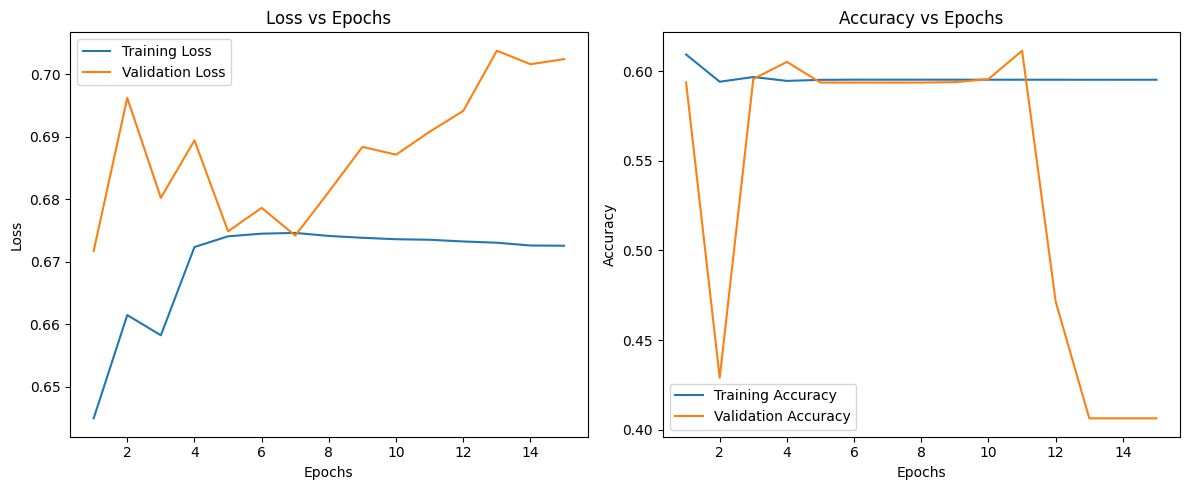

In [ ]:

# Inicializar el modelo, loss function, optimizer y scheduler
model = VisionTransformer(
                img_size=96,
                patch_size=16,
                in_chans=3,
                embed_dim=768,

                n_classes=2,
                depth=12,
                n_heads=12,
                mlp_ratio=4.,
                qkv_bias=True,
                p=0.2,
                attn_p=0.2
                         ).to(device)
criterion = nn.CrossEntropyLoss().to(device)
optimizer = optim.Adam(model.parameters(), lr=3e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

num_epochs = 15

train_and_plot(model, train_loader, val_loader, num_epochs, criterion, optimizer, scheduler, device)

Tamaño del DataLoader de entrenamiento: 4401 batches
Cantidad de datos en el DataLoader de entrenamiento: 176020 datos
Tamaño del DataLoader de validación: 1101 batches
Cantidad de datos en el DataLoader de validación: 44005 datos


Epoch 1/20 - Validation: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 1101/1101 [01:52<00:00,  9.79it/s]


Epoch 1/20, Training Loss: 0.5543, Training Accuracy: 0.7215, Validation Loss: 1.0666, Validation Accuracy: 0.5610


Epoch 2/20 - Validation: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 1101/1101 [01:50<00:00,  9.98it/s]


Epoch 2/20, Training Loss: 0.5095, Training Accuracy: 0.7591, Validation Loss: 1.3108, Validation Accuracy: 0.5526


Epoch 3/20 - Validation: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 1101/1101 [01:50<00:00,  9.99it/s]


... (31 outputs left out)

Epoch 19/20 - Validation: 100%|████████████████████████████████████████████████████████████████████████████████████████| 1101/1101 [01:52<00:00,  9.81it/s]


Epoch 19/20, Training Loss: 0.2914, Training Accuracy: 0.8768, Validation Loss: 0.8128, Validation Accuracy: 0.7089


Epoch 20/20 - Validation: 100%|████████████████████████████████████████████████████████████████████████████████████████| 1101/1101 [01:50<00:00,  9.97it/s]


Epoch 20/20, Training Loss: 0.2857, Training Accuracy: 0.8796, Validation Loss: 0.6855, Validation Accuracy: 0.7306


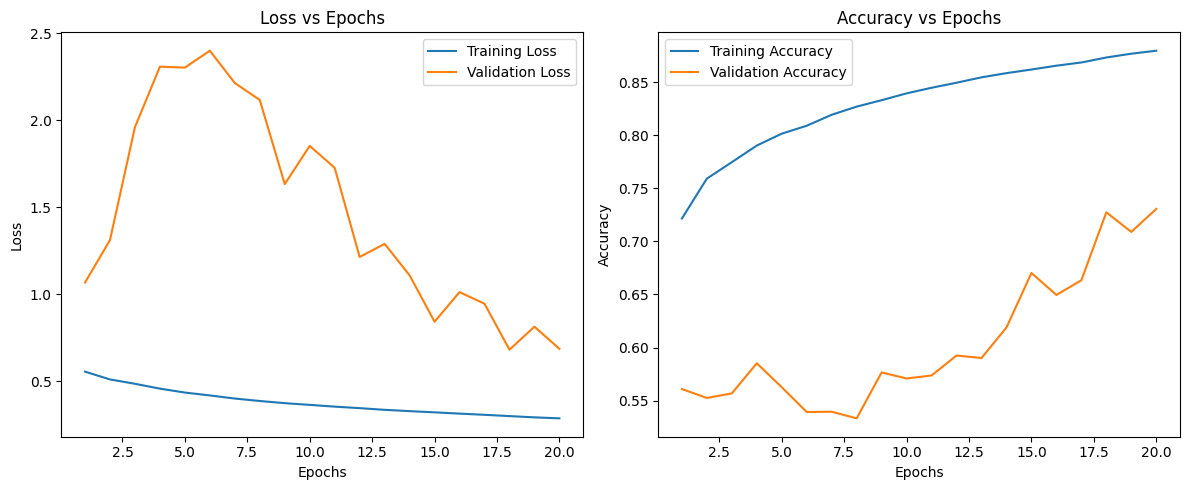

In [ ]:
# Crear dataloaders para entrenamiento y validación
train_loader = DataLoader(train_dataset, batch_size=40, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=40, shuffle=False)

# Calcular la cantidad de datos
train_data_count = len(train_loader.dataset)
val_data_count = len(val_loader.dataset)

# Imprimir el tamaño de los dataloaders y la cantidad de datos
print(f'Tamaño del DataLoader de entrenamiento: {len(train_loader)} batches')
print(f'Cantidad de datos en el DataLoader de entrenamiento: {train_data_count} datos')
print(f'Tamaño del DataLoader de validación: {len(val_loader)} batches')
print(f'Cantidad de datos en el DataLoader de validación: {val_data_count} datos')

# Inicializar el modelo, loss function y optimizer
model = VisionTransformer(
                img_size=96,
                patch_size=16,
                in_chans=3,
                embed_dim=768,
                n_classes=2,

                depth=12,
                n_heads=12,
                mlp_ratio=3.,
                qkv_bias=True,
                p=0.2,
                attn_p=0.2
                         ).to(device)
criterion = nn.CrossEntropyLoss().to(device)
optimizer = optim.Adam(model.parameters(), lr=3e-6)
num_epochs = 20

train_and_plot(model, train_loader, val_loader, num_epochs, criterion, optimizer, device)

In [ ]:
 # Crear dataloaders para entrenamiento y validación
train_loader = DataLoader(train_dataset, batch_size=40, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=40, shuffle=False)

# Calcular la cantidad de datos
train_data_count = len(train_loader.dataset)
val_data_count = len(val_loader.dataset)

# Imprimir el tamaño de los dataloaders y la cantidad de datos
print(f'Tamaño del DataLoader de entrenamiento: {len(train_loader)} batches')
print(f'Cantidad de datos en el DataLoader de entrenamiento: {train_data_count} datos')
print(f'Tamaño del DataLoader de validación: {len(val_loader)} batches')
print(f'Cantidad de datos en el DataLoader de validación: {val_data_count} datos')

# Inicializar el modelo, loss function y optimizer
model = VisionTransformer(
                img_size=96,
                patch_size=16,
                in_chans=4,
                embed_dim=768,
                n_classes=2,

                depth=12,
                n_heads=12,
                mlp_ratio=4.,
                qkv_bias=True,
                p=0.2,
                attn_p=0.2
                         ).to(device)
criterion = nn.CrossEntropyLoss().to(device)
optimizer = optim.Adam(model.parameters(), lr=3e-5)
num_epochs = 20

train_and_plot(model, train_loader, val_loader, num_epochs, criterion, optimizer, device)